Здесь будем проектировать модель классификации для начала.

In [1]:
from pathlib import Path
import os

from tqdm import tqdm

import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, DataLoader
from torch import nn
from torch import optim

In [19]:
dir_path=Path().cwd().parent

data_dir_path=dir_path/'data/severstal-steel-defect-detection'
assert data_dir_path.exists()

images_train_dir=data_dir_path/'train_images'
images_val_dir=data_dir_path/'test_images'

In [7]:
random_state=4223

In [8]:
cuda_is_available = torch.cuda.is_available()
mps_is_available = torch.mps.is_available()

if cuda_is_available:
    device='cuda'
    print(torch.cuda.get_device_name())
elif mps_is_available:
    device='mps'
    print(torch._C._mps_get_name())
else:
    device='cpu'


print('Device:', device)

Apple M5
Device: mps


In [9]:
train_df=pd.read_csv(data_dir_path/'train.csv')
train_df.head()

,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,0007a71bf.jpg,3,18661 28 18863 82 19091 110 19347 110 19603 11...
2,000a4bcdd.jpg,1,37607 3 37858 8 38108 14 38359 20 38610 25 388...
3,000f6bf48.jpg,4,131973 1 132228 4 132483 6 132738 8 132993 11 ...
4,0014fce06.jpg,3,229501 11 229741 33 229981 55 230221 77 230468...


In [10]:
all_images=sorted(os.listdir(images_train_dir))
images_df = pd.DataFrame({
    "ImageId": sorted(all_images)
})

images_df["has_defect"] = images_df["ImageId"].isin(train_df['ImageId']).astype(int)


images_df=images_df.merge(
    train_df,
    on='ImageId',
    how='left'
)

images_df['ClassId']=images_df['ClassId'].fillna(0)
images_df['EncodedPixels']=images_df['EncodedPixels'].fillna('0')

images_df.head()

,ImageId,has_defect,ClassId,EncodedPixels
0,0002cc93b.jpg,1,1.0,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,00031f466.jpg,0,0.0,0
2,000418bfc.jpg,0,0.0,0
3,000789191.jpg,0,0.0,0
4,0007a71bf.jpg,1,3.0,18661 28 18863 82 19091 110 19347 110 19603 11...


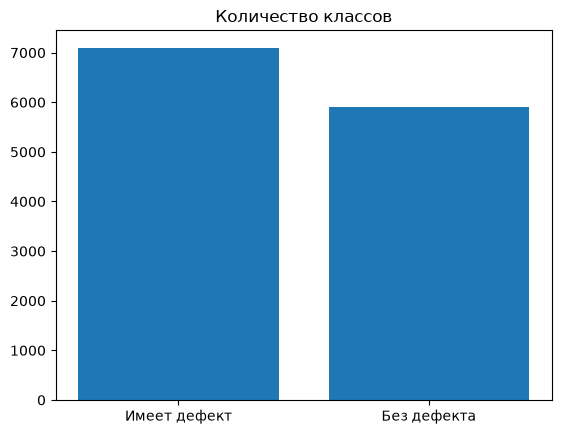

In [11]:
target_counts=images_df.has_defect.value_counts()

plt.title('Количество классов')
plt.bar(['Имеет дефект', 'Без дефекта'], target_counts)
plt.show()

In [12]:
df_train, df_val = train_test_split(images_df, test_size=0.2, stratify=images_df.ClassId, random_state=random_state)

print(f'Train size: {df_train.shape}')
print(f'Val size: {df_val.shape}')

Train size: (10397, 4)
Val size: (2600, 4)


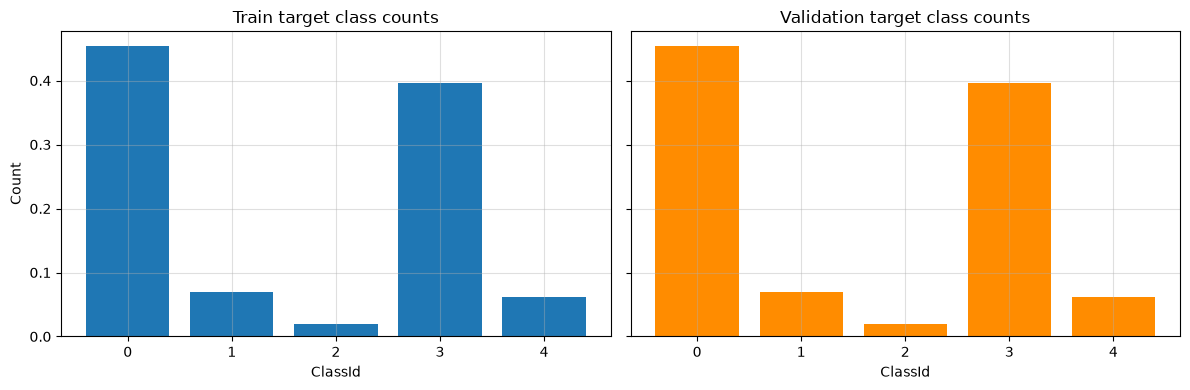

In [13]:
train_target_counts = df_train.ClassId.value_counts(normalize=True).sort_index()
val_target_counts = df_val.ClassId.value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].bar(train_target_counts.index, train_target_counts)
axes[0].set_title('Train target class counts')
axes[0].set_xlabel('ClassId')
axes[0].set_ylabel('Count')
axes[0].grid(alpha=0.4)

axes[1].bar(val_target_counts.index, val_target_counts, color='darkorange')
axes[1].set_title('Validation target class counts')
axes[1].set_xlabel('ClassId')
axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.show()

In [20]:
class ClassificationDataset(Dataset):
    def __init__(self, data_df, images_dir):
        self.data_df=data_df
        self.images_dir=images_dir

    def __len__(self):
        return len(self.data_df)

    def __getitem__(self, index):
        row=self.data_df.iloc[index]

        img_path=self.images_dir/row.ImageId

        img=cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        img=cv2.resize(img, (512, 128))

        img=torch.tensor(img) / 255.0
        img=img.unsqueeze(0)

        label = torch.tensor(row.has_defect.item(), dtype=torch.float)
        return img, label

In [34]:
batch_size=64

In [36]:
train_dataset=ClassificationDataset(df_train, images_train_dir)
val_dataset=ClassificationDataset(df_val, images_train_dir)


train_dataloader=DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,

)

val_dataloader=DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    
)

In [37]:
class CnnClassifier(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()

        self.features=nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d(2),
            nn.Flatten()
        )

        self.fcn=nn.Sequential(
            nn.Linear(64*2*2, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        features_extracted=self.features(x)

        out = self.fcn(features_extracted)
        return out

In [39]:
model = CnnClassifier().to(device)

optimizer=optim.Adam(model.parameters(), lr=0.001)
loss_fn=nn.BCEWithLogitsLoss()

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

In [ ]:
epochs = 25
history = {
    'epoch': [],
    'train_loss': [],
    'val_loss': [],
    'lr': []
}

for epoch in range(epochs):
    train_running_loss = 0.0
    val_running_loss = 0.0

    model.train()
    for img, labels in tqdm(train_dataloader):
        optimizer.zero_grad()

        img, labels = img.to(device), labels.to(device)
        predict = model(img)

        loss = loss_fn(predict.squeeze(1), labels)
        loss.backward()
        optimizer.step()

        train_running_loss += loss.item()

    model.eval()
    with torch.no_grad():
        for img, labels in tqdm(val_dataloader):
            img, labels = img.to(device), labels.to(device)
            predict = model(img)

            loss = loss_fn(predict.squeeze(1), labels)
            val_running_loss += loss.item()

    

    # Средний loss за эпоху
    train_loss = train_running_loss / len(train_dataloader)
    val_loss = val_running_loss / len(val_dataloader)

    scheduler.step(val_loss)

    # Заполнение history
    history['epoch'].append(epoch + 1)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['lr'].append(optimizer.param_groups[0]['lr'])

    print(f'Epoch {epoch + 1}')
    print(f'Train loss = {train_loss:.4f}')
    print(f'Val loss = {val_loss:.4f}')
    print(f"LR = {optimizer.param_groups[0]['lr']:.2e}")
    print('-' * 30)

100%|██████████| 41/41 [00:05<00:00,  8.08it/s]


Epoch 1
Train loss = 0.6322
Val loss = 0.5449
LR = 1.00e-03
------------------------------


100%|██████████| 41/41 [00:05<00:00,  8.02it/s]


Epoch 2
Train loss = 0.5426
Val loss = 0.5385
LR = 1.00e-03
------------------------------


100%|██████████| 41/41 [00:05<00:00,  7.97it/s]


Epoch 3
Train loss = 0.5250
Val loss = 0.4979
LR = 1.00e-03
------------------------------


... (40 outputs left out)

100%|██████████| 41/41 [00:05<00:00,  7.94it/s]


Epoch 24
Train loss = 0.3380
Val loss = 0.3434
LR = 1.00e-03
------------------------------


100%|██████████| 41/41 [00:05<00:00,  7.91it/s]

Epoch 25
Train loss = 0.3301
Val loss = 0.3391
LR = 1.00e-03
------------------------------


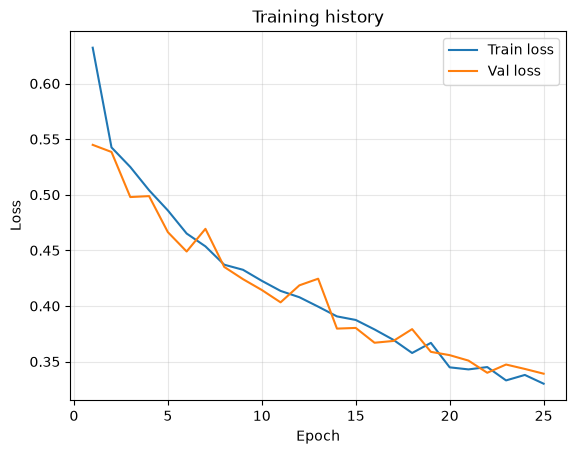

In [48]:
history_df = pd.DataFrame(history)

plt.plot(history_df['epoch'], history_df['train_loss'], label='Train loss')
plt.plot(history_df['epoch'], history_df['val_loss'], label='Val loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training history')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [50]:
model.eval()

example_input = torch.randn(1, 1, 128, 512)

model_save_dir=dir_path/'models'
model_save_dir.mkdir(exist_ok=True)

torch.onnx.export(
    model.to('cpu'),
    (example_input,),
    model_save_dir/"cnn_classifier_v1.onnx",
    input_names=["images"],
    output_names=["logits"],
    dynamo=True
)

[torch.onnx] Obtain model graph for `CnnClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CnnClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


ONNXProgram(
    model=
        <
            ir_version=10,
            opset_imports={'': 20},
            producer_name='pytorch',
            producer_version='2.15.0',
            domain=None,
            model_version=None,
        >
        graph(
            name=main_graph,
            inputs=(
                %"images"<FLOAT,[1,1,128,512]>
            ),
            outputs=(
                %"logits"<FLOAT,[1,1]>
            ),
            initializers=(
                %"features.0.weight"<FLOAT,[16,1,3,3]>{TorchTensor(...)},
                %"features.0.bias"<FLOAT,[16]>{TorchTensor(...)},
                %"features.3.weight"<FLOAT,[32,16,3,3]>{TorchTensor(...)},
                %"features.3.bias"<FLOAT,[32]>{TorchTensor(...)},
                %"features.6.weight"<FLOAT,[64,32,3,3]>{TorchTensor(...)},
                %"features.6.bias"<FLOAT,[64]>{TorchTensor(...)},
                %"fcn.0.weight"<FLOAT,[128,256]>{TorchTensor(...)},
                %"fcn.0.bias"<FLOAT,[128